# Experiment 11: Project LAST EXIT — Intelligent Disaster Evacuation System

**Aim:** Build a small, explainable prototype that coordinates rescue teams and helps people evacuate safely during a simulated flood emergency.

> **Safety note:** This is an educational simulation using invented locations, capacities, travel times, and reports. It is not for real-world emergency dispatch or operational decisions.

## What this notebook demonstrates
1. **Knowledge representation:** Areas, rescue teams, shelters, routes, and relationships represented as Python dictionaries and a graph.
2. **Rule-based reasoning:** IF–THEN rules using forward-chaining-style priority checks.
3. **Uncertainty:** Fuzzy-style risk scoring based on uncertain flood level, road condition, and report confidence.
4. **Resource allocation:** Assign people to reachable shelters while respecting capacity and rescue-team capacity.
5. **Multi-agent coordination:** A simplified Contract Net Protocol (CNP): a task is announced, available teams bid based on travel time/capacity, and a coordinator awards the task while preventing double-booking.
6. **Simulation and evaluation:** Compare a baseline with an unexpected event (route blocked and shelter unavailable); report evacuation time, resource use, and safely evacuated people, with plots.

### Scenario
A flood affects three neighborhoods—**Riverside**, **Market Ward**, and **Hill Colony**. Rescue teams operate from different bases. People must be moved to shelters through roads whose conditions may change. The system prioritizes urgent areas, assigns teams, and adapts when a route or shelter becomes unavailable.


## Task 0 — Imports and scenario knowledge base

We use only common Python libraries. The network is a graph: nodes are locations, and edges are roads with travel times and condition estimates. Areas, teams, and shelters are separate structured records.

**How to explain this:** Knowledge representation means encoding the important entities and relationships in a form the program can reason over. Here, dictionaries represent entities and a NetworkX graph represents road connectivity.


In [ ]:
import copy
import heapq
import math
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

random.seed(7)
np.random.seed(7)

# Locations and roads. travel_min is nominal one-way travel time.
G_BASE = nx.Graph()
roads = [
    ("Team Base North", "Riverside", 6, 0.90),
    ("Team Base North", "Market Junction", 5, 0.95),
    ("Market Junction", "Riverside", 4, 0.80),
    ("Market Junction", "Market Ward", 3, 0.90),
    ("Market Junction", "Hill Road", 5, 0.75),
    ("Hill Road", "Hill Colony", 4, 0.85),
    ("Hill Road", "Shelter Central", 6, 0.90),
    ("Riverside", "Shelter East", 7, 0.80),
    ("Market Ward", "Shelter Central", 5, 0.90),
    ("Hill Colony", "Shelter North", 5, 0.95),
    ("Shelter East", "Shelter Central", 8, 0.90),
]
for u, v, travel, condition in roads:
    G_BASE.add_edge(u, v, travel_min=travel, condition=condition, blocked=False)

# Affected areas: people_waiting are the people currently needing evacuation.
AREAS_BASE = {
    "Riverside": {
        "people_waiting": 85, "flood_level": 0.88,
        "road_uncertainty": 0.25, "report_confidence": 0.92
    },
    "Market Ward": {
        "people_waiting": 60, "flood_level": 0.63,
        "road_uncertainty": 0.20, "report_confidence": 0.82
    },
    "Hill Colony": {
        "people_waiting": 45, "flood_level": 0.42,
        "road_uncertainty": 0.35, "report_confidence": 0.72
    }
}

# Rescue teams: each team can evacuate up to its capacity per trip in this toy model.
TEAMS_BASE = {
    "Team Alpha": {"location": "Team Base North", "capacity": 45, "available": True},
    "Team Bravo": {"location": "Market Junction", "capacity": 35, "available": True},
    "Team Charlie": {"location": "Hill Road", "capacity": 25, "available": True},
}

# Shelters have finite capacity. Initial occupied capacity is zero.
SHELTERS_BASE = {
    "Shelter East": {"capacity": 70, "occupied": 0},
    "Shelter Central": {"capacity": 90, "occupied": 0},
    "Shelter North": {"capacity": 55, "occupied": 0},
}

print("Affected areas:")
display(pd.DataFrame(AREAS_BASE).T)
print("\nRescue teams:")
display(pd.DataFrame(TEAMS_BASE).T)
print("\nShelters:")
display(pd.DataFrame(SHELTERS_BASE).T)


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-618bulif because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Affected areas:


,people_waiting,flood_level,road_uncertainty,report_confidence
Riverside,85.0,0.88,0.25,0.92
Market Ward,60.0,0.63,0.20,0.82
Hill Colony,45.0,0.42,0.35,0.72



Rescue teams:


,location,capacity,available
Team Alpha,Team Base North,45,True
Team Bravo,Market Junction,35,True
Team Charlie,Hill Road,25,True



Shelters:


,capacity,occupied
Shelter East,70,0
Shelter Central,90,0
Shelter North,55,0


## Task 1 — Knowledge representation and relationships

We visualize the road network. Edge labels show nominal travel time. A blocked road will be represented by an edge attribute (`blocked=True`), and route planning will avoid that edge.

This is a simple **relational graph representation**: a path from a team to an affected area and then to a shelter establishes whether the assignment is feasible.


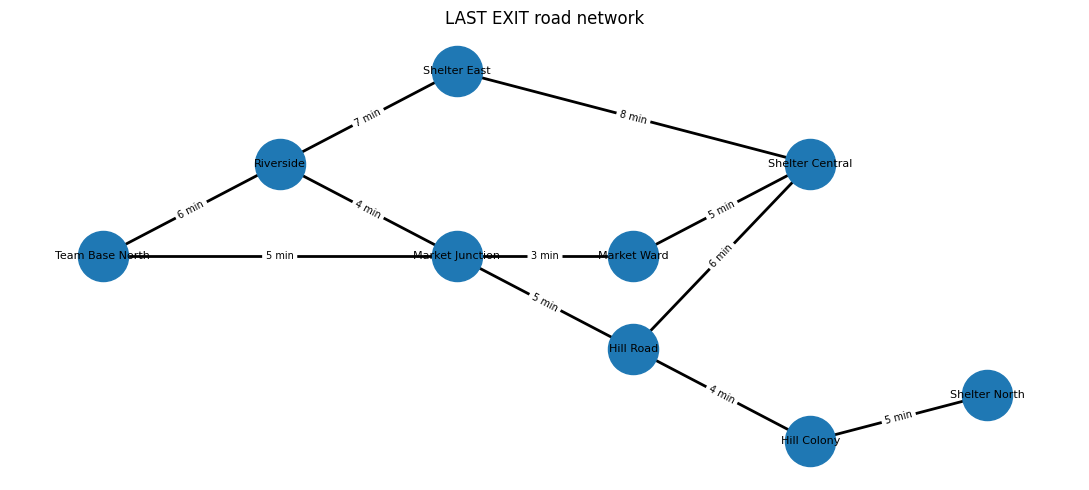

In [ ]:
def draw_network(graph, title="LAST EXIT road network"):
    pos = {
        "Team Base North": (0, 2),
        "Riverside": (1, 3),
        "Market Junction": (2, 2),
        "Market Ward": (3, 2),
        "Hill Road": (3, 1),
        "Hill Colony": (4, 0),
        "Shelter East": (2, 4),
        "Shelter Central": (4, 3),
        "Shelter North": (5, 0.5),
    }
    plt.figure(figsize=(11, 5))
    nx.draw_networkx_nodes(graph, pos, node_size=1300)
    nx.draw_networkx_labels(graph, pos, font_size=8)
    edge_labels = {
        (u, v): f"{d['travel_min']} min" + (" BLOCKED" if d.get("blocked") else "")
        for u, v, d in graph.edges(data=True)
    }
    nx.draw_networkx_edges(
        graph, pos,
        edgelist=[(u, v) for u, v, d in graph.edges(data=True) if not d.get("blocked", False)],
        width=2
    )
    nx.draw_networkx_edges(
        graph, pos,
        edgelist=[(u, v) for u, v, d in graph.edges(data=True) if d.get("blocked", False)],
        style="dashed", width=2
    )
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels, font_size=7)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

draw_network(G_BASE)


## Task 2 — Rule-based reasoning with forward-chaining-style rules

The system evaluates known facts about each area, fires rules, and derives a priority/action. In a production system, this would often be implemented as an agenda of rules; here, a readable ordered function demonstrates the same core idea.

Priority rules:
- **IF** flood level is high **OR** risk score is high, **THEN** assign *Critical* priority.
- **ELSE IF** flood level or risk is moderate, **THEN** assign *High* priority.
- **ELSE** assign *Standard* priority.
- **IF** confidence in the report is low, **THEN** flag for verification while keeping risk-based evacuation planning active.

Priority is based on risk, not on the identity of a neighborhood.


In [ ]:
def fuzzy_risk(area):
    """A transparent fuzzy-style score in [0, 1].

    This is a weighted fuzzy-inspired scoring function, not a full fuzzy
    inference library. Inputs are normalized to [0,1].
    Higher flood level and road uncertainty increase risk; lower report
    confidence increases uncertainty and therefore adds a smaller risk term.
    """
    flood = float(area["flood_level"])
    road_uncertainty = float(area["road_uncertainty"])
    confidence = float(area["report_confidence"])
    uncertainty = 1.0 - confidence
    score = 0.60 * flood + 0.25 * road_uncertainty + 0.15 * uncertainty
    return min(1.0, max(0.0, score))

def infer_priority(area):
    """Forward-chaining-style inference: derive facts from observed inputs."""
    risk = fuzzy_risk(area)
    fired_rules = []

    # Rule 1: high flood or very high combined risk.
    if area["flood_level"] >= 0.80 or risk >= 0.72:
        priority = "Critical"
        action = "Immediate evacuation; dispatch a team as soon as a safe route is available."
        fired_rules.append("R1")
    # Rule 2: medium-to-high risk.
    elif area["flood_level"] >= 0.55 or risk >= 0.48:
        priority = "High"
        action = "Evacuate promptly; verify road reports while dispatching."
        fired_rules.append("R2")
    else:
        priority = "Standard"
        action = "Prepare evacuation and continue monitoring conditions."
        fired_rules.append("R3")

    if area["report_confidence"] < 0.75:
        fired_rules.append("R4")
        verification = "Verify the report with another source."
    else:
        verification = "Report confidence acceptable for this simulation."

    return {
        "risk_score": round(risk, 3),
        "priority": priority,
        "action": action,
        "rules_fired": ", ".join(fired_rules),
        "verification": verification
    }

priority_rows = []
for area_name, area in AREAS_BASE.items():
    result = infer_priority(area)
    priority_rows.append({"area": area_name, **result})
priority_df = pd.DataFrame(priority_rows).sort_values(
    "risk_score", ascending=False
)
display(priority_df)


,area,risk_score,priority,action,rules_fired,verification
0,Riverside,0.603,Critical,Immediate evacuation; dispatch a team as soon ...,R1,Report confidence acceptable for this simulation.
1,Market Ward,0.455,High,Evacuate promptly; verify road reports while d...,R2,Report confidence acceptable for this simulation.
2,Hill Colony,0.382,Standard,Prepare evacuation and continue monitoring con...,"R3, R4",Verify the report with another source.


## Task 3 — Handling uncertainty

Flood measurements, road reports, and emergency calls may be incomplete or noisy. We combine three normalized inputs:
- flood level (higher = more danger),
- road uncertainty (higher = less reliable access),
- report uncertainty (lower report confidence = greater uncertainty).

The resulting risk score is not a real-world probability of injury. It is a transparent heuristic for demonstrating uncertain reasoning. We'll also test how a low-confidence report affects the priority and verification note.


,case,risk_score,priority,rules_fired,verification
0,"Reported severe flood, confident report",0.585,Critical,R1,Report confidence acceptable for this simulation.
1,"Moderate flood, uncertain road",0.608,High,"R2, R4",Verify the report with another source.
2,"Lower flood, uncertain report",0.367,Standard,"R3, R4",Verify the report with another source.


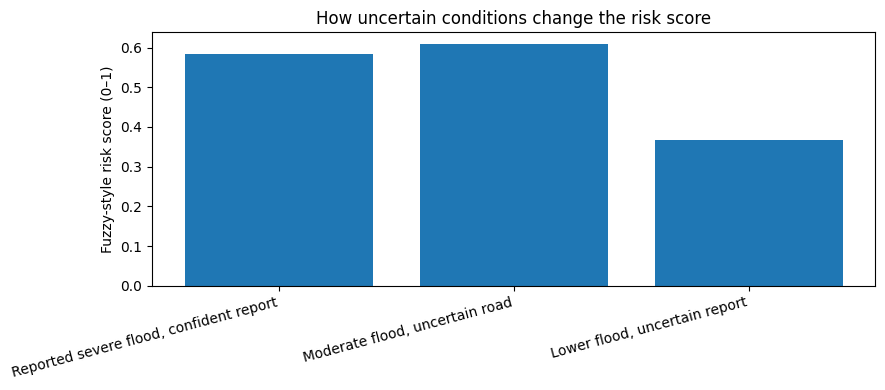

In [ ]:
uncertainty_cases = [
    ("Reported severe flood, confident report", {
        "flood_level": 0.90, "road_uncertainty": 0.15, "report_confidence": 0.95
    }),
    ("Moderate flood, uncertain road", {
        "flood_level": 0.58, "road_uncertainty": 0.80, "report_confidence": 0.60
    }),
    ("Lower flood, uncertain report", {
        "flood_level": 0.35, "road_uncertainty": 0.30, "report_confidence": 0.45
    })
]

uncertainty_rows = []
for label, case in uncertainty_cases:
    uncertainty_rows.append({
        "case": label,
        **infer_priority(case)
    })
uncertainty_df = pd.DataFrame(uncertainty_rows)
display(uncertainty_df[["case", "risk_score", "priority", "rules_fired", "verification"]])

plt.figure(figsize=(9, 4))
plt.bar(uncertainty_df["case"], uncertainty_df["risk_score"])
plt.ylabel("Fuzzy-style risk score (0–1)")
plt.title("How uncertain conditions change the risk score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## Task 4 — Resource allocation and route planning

We use Dijkstra's shortest-path algorithm with **effective road time**. Roads with `blocked=True` are excluded. A road in poor condition increases effective travel time, so the route planner prefers safer/reliable roads when available.

Allocation rules:
1. Process areas in descending priority/risk order.
2. Consider only available teams that can reach the area.
3. Choose the team with the lowest travel time, breaking ties by larger capacity.
4. Choose a reachable shelter with enough remaining capacity, favoring shorter travel time.
5. Evacuate up to the minimum of remaining people, team capacity, and shelter capacity.
6. Mark a team as assigned once for this single-trip simulation, preventing double-booking.

This is a simplified planning model. Real operations require live maps, multiple trips, accessibility needs, safety constraints, and human incident command.


In [ ]:
def effective_edge_time(data):
    """Road time penalty: poor road condition increases travel time.
    A blocked edge is excluded by shortest_path_time().
    """
    condition = max(0.20, float(data.get("condition", 1.0)))
    return float(data["travel_min"]) / condition

def shortest_path_time(graph, source, target):
    """Dijkstra shortest travel time, skipping blocked roads; returns (time, path)."""
    if source not in graph or target not in graph:
        return math.inf, []
    distances = {node: math.inf for node in graph.nodes}
    previous = {}
    distances[source] = 0.0
    queue = [(0.0, source)]
    while queue:
        dist, node = heapq.heappop(queue)
        if dist > distances[node]:
            continue
        if node == target:
            break
        for neighbor, data in graph[node].items():
            if data.get("blocked", False):
                continue
            candidate = dist + effective_edge_time(data)
            if candidate < distances[neighbor]:
                distances[neighbor] = candidate
                previous[neighbor] = node
                heapq.heappush(queue, (candidate, neighbor))
    if not math.isfinite(distances[target]):
        return math.inf, []
    path = [target]
    while path[-1] != source:
        path.append(previous[path[-1]])
    path.reverse()
    return distances[target], path

def allocate_resources(graph, areas, teams, shelters):
    """Allocate one team and one shelter per task using a simple CNP-like auction.

    Each unserved area is a task. Available teams submit bids based on route time
    and capacity. The coordinator awards the task to the best feasible bid.
    Each team can receive at most one task in this one-trip scenario.
    """
    areas = copy.deepcopy(areas)
    teams = copy.deepcopy(teams)
    shelters = copy.deepcopy(shelters)

    # Derive risk/priority for each area and process highest risk first.
    ordered_areas = sorted(
        areas.items(),
        key=lambda item: fuzzy_risk(item[1]),
        reverse=True
    )
    assignments = []
    team_used = set()
    total_people = 0
    completion_times = []

    for area_name, area in ordered_areas:
        people = int(area["people_waiting"])
        if people <= 0:
            continue

        # Contract Net Protocol (simplified): teams bid for the area.
        bids = []
        for team_name, team in teams.items():
            if not team["available"] or team_name in team_used:
                continue
            travel, path = shortest_path_time(graph, team["location"], area_name)
            if math.isfinite(travel):
                # A small preference for teams with enough capacity.
                capacity_bonus = min(team["capacity"], people) * 0.01
                bid_score = travel - capacity_bonus
                bids.append((bid_score, travel, team_name, path))

        if not bids:
            assignments.append({
                "area": area_name, "team": "None", "shelter": "None",
                "people_evacuated": 0, "travel_min": np.nan,
                "completion_min": np.nan, "status": "No reachable available team"
            })
            continue

        bids.sort(key=lambda x: (x[0], x[1]))
        _, team_to_area_time, team_name, path_to_area = bids[0]
        team = teams[team_name]

        # Choose the closest shelter that is reachable and has remaining capacity.
        shelter_options = []
        for shelter_name, shelter in shelters.items():
            remaining_capacity = shelter["capacity"] - shelter["occupied"]
            if remaining_capacity <= 0:
                continue
            travel, path = shortest_path_time(graph, area_name, shelter_name)
            if math.isfinite(travel):
                shelter_options.append((travel, shelter_name, path, remaining_capacity))

        if not shelter_options:
            assignments.append({
                "area": area_name, "team": team_name, "shelter": "None",
                "people_evacuated": 0, "travel_min": round(team_to_area_time, 1),
                "completion_min": np.nan, "status": "No reachable shelter with capacity"
            })
            team_used.add(team_name)
            continue

        shelter_options.sort(key=lambda x: x[0])
        shelter_time, shelter_name, path_to_shelter, shelter_remaining = shelter_options[0]

        evacuated = min(people, int(team["capacity"]), int(shelter_remaining))
        if evacuated <= 0:
            status = "No capacity available"
            completion = np.nan
        else:
            # Simple estimate: team goes to area, then shelter. No return trip.
            completion = team_to_area_time + shelter_time
            status = "Evacuated safely to assigned shelter"
            shelters[shelter_name]["occupied"] += evacuated
            areas[area_name]["people_waiting"] -= evacuated
            total_people += evacuated
            completion_times.append(completion)

        assignments.append({
            "area": area_name,
            "team": team_name,
            "shelter": shelter_name,
            "people_evacuated": evacuated,
            "travel_min": round(team_to_area_time + shelter_time, 1),
            "completion_min": round(completion, 1) if math.isfinite(completion) else np.nan,
            "status": status,
            "route_to_area": " → ".join(path_to_area),
            "route_to_shelter": " → ".join(path_to_shelter)
        })
        team_used.add(team_name)

    result_df = pd.DataFrame(assignments)
    metrics = {
        "people_waiting_initial": sum(a["people_waiting"] for a in AREAS_BASE.values()),
        "people_evacuated": int(total_people),
        "people_remaining": int(sum(a["people_waiting"] for a in areas.values())),
        "teams_used": int(len(team_used)),
        "shelters_used": int(result_df.loc[result_df["people_evacuated"] > 0, "shelter"].nunique())
            if len(result_df) else 0,
        "estimated_evacuation_time_min": round(max(completion_times), 1) if completion_times else np.nan,
        "safe_evacuation_rate": round(
            total_people / max(1, sum(a["people_waiting"] for a in AREAS_BASE.values())), 3
        )
    }
    return result_df, metrics, shelters

baseline_graph = copy.deepcopy(G_BASE)
baseline_assignments, baseline_metrics, baseline_shelters = allocate_resources(
    baseline_graph, AREAS_BASE, TEAMS_BASE, SHELTERS_BASE
)

print("Baseline assignments:")
display(baseline_assignments)
print("Baseline metrics:")
display(pd.DataFrame([baseline_metrics]))
print("Shelter occupancy after allocation:")
display(pd.DataFrame(baseline_shelters).T)


Baseline assignments:


,area,team,shelter,people_evacuated,travel_min,completion_min,status,route_to_area,route_to_shelter
0,Riverside,Team Bravo,Shelter East,35,13.8,13.8,Evacuated safely to assigned shelter,Market Junction → Riverside,Riverside → Shelter East
1,Market Ward,Team Alpha,Shelter Central,45,14.2,14.2,Evacuated safely to assigned shelter,Team Base North → Market Junction → Market Ward,Market Ward → Shelter Central
2,Hill Colony,Team Charlie,Shelter North,25,10.0,10.0,Evacuated safely to assigned shelter,Hill Road → Hill Colony,Hill Colony → Shelter North


Baseline metrics:


,people_waiting_initial,people_evacuated,people_remaining,teams_used,shelters_used,estimated_evacuation_time_min,safe_evacuation_rate
0,190,105,85,3,3,14.2,0.553


Shelter occupancy after allocation:


,capacity,occupied
Shelter East,70,35
Shelter Central,90,45
Shelter North,55,25


## Task 5 — Multi-agent coordination with the Contract Net Protocol (CNP)

**CNP overview**
1. **Manager announces a task:** for example, evacuate Riverside.
2. **Agents bid:** available rescue teams estimate travel time and capacity.
3. **Manager evaluates bids:** select the best feasible team.
4. **Award and execute:** assign one team and reserve a shelter.
5. **Conflict prevention:** a team is marked used after assignment, and shelter capacity is decremented so it cannot be overbooked.

This notebook uses a simplified CNP-inspired coordinator within the allocation function. It is not a full distributed multi-agent implementation, but it shows the key concepts of task announcement, bidding, award, and resource-conflict prevention.


In [ ]:
# Show the auction/bid concept explicitly for one example task.
target_area = "Riverside"
bid_rows = []
for team_name, team in TEAMS_BASE.items():
    travel, path = shortest_path_time(G_BASE, team["location"], target_area)
    if math.isfinite(travel):
        bid_rows.append({
            "team": team_name,
            "capacity": team["capacity"],
            "travel_to_Riverside_min": round(travel, 1),
            "route": " → ".join(path),
            "feasible": team["available"]
        })
    else:
        bid_rows.append({
            "team": team_name, "capacity": team["capacity"],
            "travel_to_Riverside_min": np.nan, "route": "No path", "feasible": False
        })
bids_df = pd.DataFrame(bid_rows).sort_values("travel_to_Riverside_min")
print("CNP-style bids for task: evacuate Riverside")
display(bids_df)
print("Coordinator awards the task to the feasible team with the best travel/capacity bid,")
print("then marks that team as used so it cannot be assigned a second task in this simulation.")


CNP-style bids for task: evacuate Riverside


,team,capacity,travel_to_Riverside_min,route,feasible
1,Team Bravo,35,5.0,Market Junction → Riverside,True
0,Team Alpha,45,6.7,Team Base North → Riverside,True
2,Team Charlie,25,11.7,Hill Road → Market Junction → Riverside,True


Coordinator awards the task to the feasible team with the best travel/capacity bid,
then marks that team as used so it cannot be assigned a second task in this simulation.


## Task 6 — Simulation with an unexpected event

Now introduce two disruptions:
1. The road **Market Junction ↔ Hill Road** is blocked.
2. **Shelter Central** becomes unavailable (for example, structural damage is reported).

The system should recompute routes, avoid the blocked edge, and reallocate only to shelters that remain available. Compare baseline and disrupted results.

We deliberately keep the same initial demand and team/shelter capacities so the comparison isolates the effect of the disruption.


Disrupted road network:


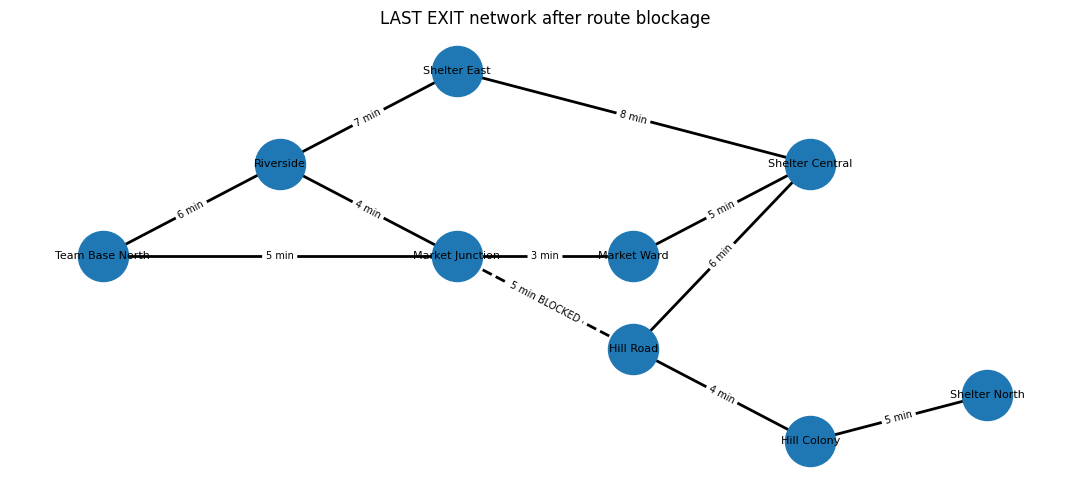

Disrupted-scenario assignments:


,area,team,shelter,people_evacuated,travel_min,completion_min,status,route_to_area,route_to_shelter
0,Riverside,Team Bravo,Shelter East,35,13.8,13.8,Evacuated safely to assigned shelter,Market Junction → Riverside,Riverside → Shelter East
1,Market Ward,Team Alpha,Shelter East,35,23.0,23.0,Evacuated safely to assigned shelter,Team Base North → Market Junction → Market Ward,Market Ward → Shelter Central → Shelter East
2,Hill Colony,Team Charlie,Shelter North,25,10.0,10.0,Evacuated safely to assigned shelter,Hill Road → Hill Colony,Hill Colony → Shelter North


Disrupted-scenario metrics:


,people_waiting_initial,people_evacuated,people_remaining,teams_used,shelters_used,estimated_evacuation_time_min,safe_evacuation_rate
0,190,95,95,3,2,23.0,0.5


Shelter occupancy after disruption:


,capacity,occupied
Shelter East,70,70
Shelter Central,0,0
Shelter North,55,25


In [ ]:
# Build the disrupted scenario without mutating the baseline.
disrupted_graph = copy.deepcopy(G_BASE)
disrupted_graph["Market Junction"]["Hill Road"]["blocked"] = True

disrupted_shelters = copy.deepcopy(SHELTERS_BASE)
disrupted_shelters["Shelter Central"]["capacity"] = 0  # unavailable shelter

disrupted_assignments, disrupted_metrics, final_disrupted_shelters = allocate_resources(
    disrupted_graph, AREAS_BASE, TEAMS_BASE, disrupted_shelters
)

print("Disrupted road network:")
draw_network(disrupted_graph, title="LAST EXIT network after route blockage")

print("Disrupted-scenario assignments:")
display(disrupted_assignments)
print("Disrupted-scenario metrics:")
display(pd.DataFrame([disrupted_metrics]))
print("Shelter occupancy after disruption:")
display(pd.DataFrame(final_disrupted_shelters).T)


## Evaluation — compare evacuation time, resource usage, and safe evacuations

Metrics:
- **People evacuated safely:** number assigned to a reachable shelter.
- **People remaining:** demand not evacuated in this one-trip simulation.
- **Estimated evacuation time:** maximum estimated team travel time (team → area → shelter) among successful assignments. It excludes waiting, loading, traffic dynamics, and return trips.
- **Teams used:** number of teams committed.
- **Shelters used:** number of distinct shelters receiving evacuees.
- **Safe evacuation rate:** evacuated people divided by initial people waiting.

These are simplified simulation metrics—not real response-time predictions.


,scenario,people_waiting_initial,people_evacuated,people_remaining,teams_used,shelters_used,estimated_evacuation_time_min,safe_evacuation_rate
0,Baseline,190,105,85,3,3,14.2,0.553
1,Route blocked + Shelter Central unavailable,190,95,95,3,2,23.0,0.500


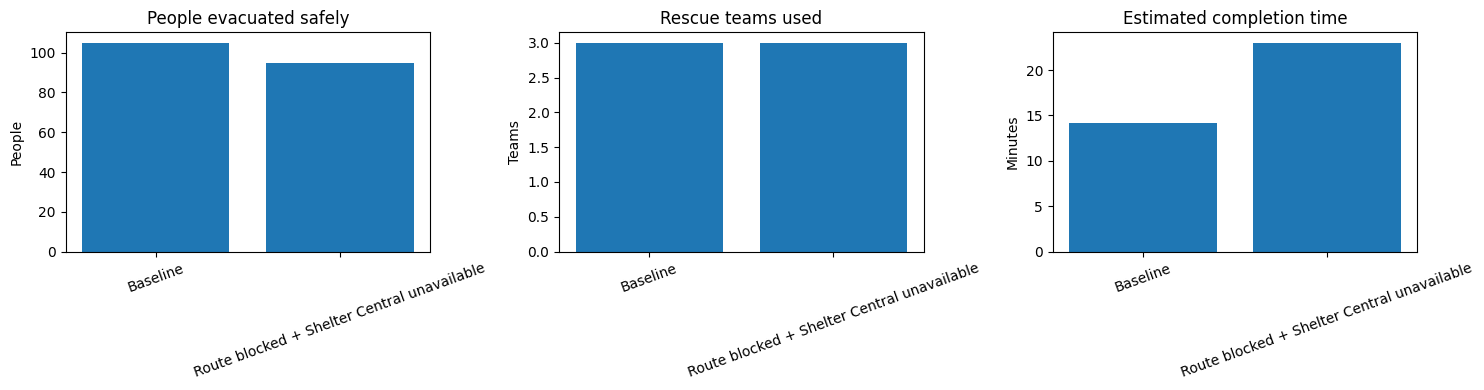

Change after disruption:
- people_evacuated: baseline=105, disrupted=95
- people_remaining: baseline=85, disrupted=95
- teams_used: baseline=3, disrupted=3
- shelters_used: baseline=3, disrupted=2
- estimated_evacuation_time_min: baseline=14.2, disrupted=23.0
- safe_evacuation_rate: baseline=0.553, disrupted=0.5


In [ ]:
metrics_compare = pd.DataFrame([
    {"scenario": "Baseline", **baseline_metrics},
    {"scenario": "Route blocked + Shelter Central unavailable", **disrupted_metrics}
])
display(metrics_compare)

# Plot key metrics for visual comparison.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(metrics_compare["scenario"], metrics_compare["people_evacuated"])
axes[0].set_title("People evacuated safely")
axes[0].set_ylabel("People")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(metrics_compare["scenario"], metrics_compare["teams_used"])
axes[1].set_title("Rescue teams used")
axes[1].set_ylabel("Teams")
axes[1].tick_params(axis="x", rotation=20)

axes[2].bar(metrics_compare["scenario"], metrics_compare["estimated_evacuation_time_min"])
axes[2].set_title("Estimated completion time")
axes[2].set_ylabel("Minutes")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Change after disruption:")
for metric in ["people_evacuated", "people_remaining", "teams_used", "shelters_used",
               "estimated_evacuation_time_min", "safe_evacuation_rate"]:
    before = baseline_metrics.get(metric)
    after = disrupted_metrics.get(metric)
    print(f"- {metric}: baseline={before}, disrupted={after}")


## Optional test — make the event more severe

This cell demonstrates how the system responds if the East route from Riverside is also blocked. It re-runs the allocator using the modified graph. Observe whether it finds another route, uses another shelter, or reports that no feasible assignment exists.


In [ ]:
severe_graph = copy.deepcopy(disrupted_graph)
severe_graph["Riverside"]["Shelter East"]["blocked"] = True

severe_assignments, severe_metrics, severe_final_shelters = allocate_resources(
    severe_graph, AREAS_BASE, TEAMS_BASE, disrupted_shelters
)
print("Severe-event assignments:")
display(severe_assignments)
print("Severe-event metrics:")
display(pd.DataFrame([severe_metrics]))


Severe-event assignments:


,area,team,shelter,people_evacuated,travel_min,completion_min,status,route_to_area,route_to_shelter
0,Riverside,Team Bravo,Shelter East,35,27.8,27.8,Evacuated safely to assigned shelter,Market Junction → Riverside,Riverside → Market Junction → Market Ward → Sh...
1,Market Ward,Team Alpha,Shelter East,35,23.0,23.0,Evacuated safely to assigned shelter,Team Base North → Market Junction → Market Ward,Market Ward → Shelter Central → Shelter East
2,Hill Colony,Team Charlie,Shelter North,25,10.0,10.0,Evacuated safely to assigned shelter,Hill Road → Hill Colony,Hill Colony → Shelter North


Severe-event metrics:


,people_waiting_initial,people_evacuated,people_remaining,teams_used,shelters_used,estimated_evacuation_time_min,safe_evacuation_rate
0,190,95,95,3,2,27.8,0.5


## Conclusion / result

The LAST EXIT prototype demonstrates an intelligent disaster evacuation workflow:
- entities and road relationships are represented using structured records and a graph;
- rule-based inference turns uncertain conditions into priorities and recommended actions;
- a fuzzy-style score combines flood level, road uncertainty, and report confidence;
- resource allocation respects team availability, route reachability, and shelter capacity;
- a simplified Contract Net Protocol coordinates tasks through team bids and awards;
- scenario simulation measures evacuation outcomes and adapts when a road is blocked or a shelter becomes unavailable.

### Limitations
This is a deliberately small educational simulation. It uses static road times, simplified risk weights, one task per team, and one trip per team. It does not model changing water levels, vulnerable-person needs, rescue safety, real maps, communications failure, or incident-command procedures. Real deployment would require validated data, robust optimization, live updates, emergency-service oversight, and extensive testing.

## Short viva questions and answers

1. **What is knowledge representation here?** Python dictionaries store areas, teams, and shelters; a graph represents roads and travel-time relationships.
2. **What is forward chaining?** Start from known facts, fire matching IF–THEN rules, and derive new conclusions such as priority and action.
3. **Why use fuzzy-style reasoning?** Flood levels and road reports are uncertain; a graded score represents combined risk more flexibly than a single yes/no threshold.
4. **How is resource allocation performed?** Select feasible teams and shelters using reachability, travel time, team capacity, and remaining shelter capacity.
5. **What is CNP?** A coordination protocol in which a manager announces a task, agents bid, and the manager awards it to a suitable agent.
6. **How does the system handle a blocked route?** The route planner excludes blocked edges and searches for an alternative path; if no feasible path or shelter remains, it reports the failure.
7. **What metrics are compared?** People evacuated, people remaining, estimated completion time, teams used, shelters used, and evacuation rate.
8. **Why is this not suitable for real emergency dispatch?** The scenario, data, risk model, and assumptions are simplified and unvalidated; real decisions need professional oversight and reliable live information.
